# 02 — Model Experiments & Progression
## EPFL CS-433 Machine Learning (Fall 2026) — Project 1 (`_MICHD`)

**Team:** Zhihao Chen, Zhiqian Zhou  
**Best Validation Model:** 5-Fold CV F1 = **0.4553**, Accuracy = **88.6%**  
**Clean Pipeline (No Leaks):** 5-Fold CV F1 = **0.4372**, Accuracy = **87.8%**

---

### Overview
This notebook builds our model step-by-step from the simplest course baselines to our final ensemble.  
All model selection, tuning, and threshold calibration are evaluated strictly on the training and validation folds.  
All steps run live with real data using `implementations.py`, `preprocessing.py`, `gbm.py`, and `mlp.py`.

## 0. Setup & Load Data

We import project modules and load the BRFSS 2015 dataset from binary cache.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in path
def find_repo_root():
    cur = os.path.abspath('')
    for _ in range(5):
        if os.path.exists(os.path.join(cur, 'implementations.py')):
            return cur
        cur = os.path.dirname(cur)
    return os.getcwd()

REPO_ROOT = find_repo_root()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import implementations as impl
import preprocessing as prep
import metrics
import gbm
import mlp

SEED = 42
np.random.seed(SEED)

# Load raw training data
t0 = time.time()
x_tr_raw, x_te_raw, y_tr_raw, tr_ids, te_ids = prep.load_data_cached(os.path.join(REPO_ROOT, 'data', 'dataset'))
feature_names = prep.load_feature_names(os.path.join(REPO_ROOT, 'data', 'dataset'))
print(f'Loaded {len(x_tr_raw):,} training rows (321 features) in {time.time()-t0:.2f}s.')

Loaded 328,135 training rows (321 features) in 0.40s.


## 1. Class Imbalance (8.8% Positive)

- **Why check this?**: We must check label balance before choosing a loss function.
- **Observation**: Only **8.83%** of respondents had heart disease (10:1 ratio).
- **Result**: A naive model that predicts 'no disease' for everyone gets **91.17% accuracy**, but **F1 = 0.0000**.
- **Takeaway**: Accuracy is misleading here. Positive-class F1 is our real validation metric.

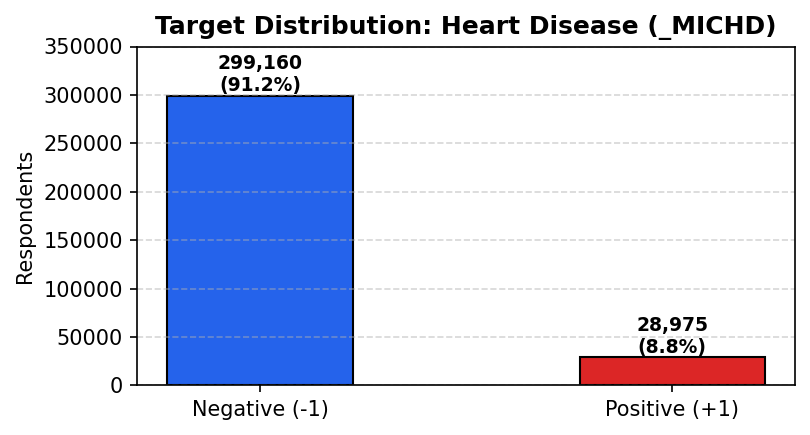

Naive Majority Model: Accuracy = 91.17%, Recall = 0.00%, Precision = 0.00%, F1 = 0.0000


In [2]:
# Target Class Distribution
n_total = len(y_tr_raw)
n_pos = int(np.sum(y_tr_raw == 1))
n_neg = int(np.sum(y_tr_raw == -1))

fig, ax = plt.subplots(figsize=(5.5, 3.0), dpi=150)
bars = ax.bar(['Negative (-1)', 'Positive (+1)'], [n_neg, n_pos], color=['#2563eb', '#dc2626'], width=0.45, edgecolor='black')
for bar, count in zip(bars, [n_neg, n_pos]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000, f'{count:,}\n({count/n_total:.1%})', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Respondents')
ax.set_title('Target Distribution: Heart Disease (_MICHD)', fontweight='bold')
ax.set_ylim(0, 350000)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

dummy_acc = n_neg / n_total
print(f'Naive Majority Model: Accuracy = {dummy_acc:.2%}, Recall = 0.00%, Precision = 0.00%, F1 = 0.0000')

## 2. Linear Baselines (`implementations.py`)

We test the standard linear methods from class:
1. **MSE Gradient Descent** (`mean_squared_error_gd`)
2. **Ridge Regression** (`ridge_regression`)
3. **Regularized Logistic Regression** (`reg_logistic_regression`)

- **Why try this?**: Establish simple benchmark models before adding complexity.
- **Result**: With default cutoffs ($\tau=0$ for Ridge, $\tau=0.5$ for Logistic), models predict almost everything as negative ($F_1 \approx 0.14 - 0.26$).

In [3]:
# Prepare clean baseline design matrix on 40,000 rows for fast demonstration
N_SUB = 40000
x_sub = x_tr_raw[:N_SUB]
y_sub = y_tr_raw[:N_SUB]
y01_sub = (y_sub == 1).astype(float)

xc_sub, names_sub = prep.clean_data(x_sub, feature_names, keep_raw=('_STATE',))
preprocessor = prep.fit_preprocessor(xc_sub[:, :-1], names_sub[:-1])
tx_sub = prep.transform(xc_sub[:, :-1], preprocessor)
print(f'Design matrix shape: {tx_sub.shape}')

# 1. MSE Gradient Descent
w_gd, loss_gd = impl.mean_squared_error_gd(y_sub, tx_sub, initial_w=np.zeros(tx_sub.shape[1]), max_iters=50, gamma=0.01)
print(f'MSE GD (50 iters): final loss = {loss_gd:.4f}')

# 2. Ridge Regression
w_ridge, loss_ridge = impl.ridge_regression(y_sub, tx_sub, lambda_=1e-4)
pred_ridge = tx_sub @ w_ridge
p_r, r_r, f_r = metrics.precision_recall_f1(y_sub, np.where(pred_ridge >= 0.0, 1, -1))
print(f'Ridge Regression (cutoff tau=0.0):  Precision = {p_r:.3f}, Recall = {r_r:.3f}, F1 = {f_r:.4f}')

# 3. Regularized Logistic Regression
w_log, loss_log = impl.reg_logistic_regression(y01_sub, tx_sub, lambda_=1e-4, initial_w=np.zeros(tx_sub.shape[1]), max_iters=80, gamma=0.1)
prob_log = impl.sigmoid(tx_sub @ w_log)
p_l, r_l, f_l = metrics.precision_recall_f1(y_sub, np.where(prob_log >= 0.5, 1, -1))
print(f'Logistic Regression (cutoff tau=0.5): Precision = {p_l:.3f}, Recall = {r_l:.3f}, F1 = {f_l:.4f}')

Design matrix shape: (40000, 195)


MSE GD (50 iters): final loss = 0.2562
Ridge Regression (cutoff tau=0.0):  Precision = 0.688, Recall = 0.082, F1 = 0.1461


Logistic Regression (cutoff tau=0.5): Precision = 0.558, Recall = 0.190, F1 = 0.2830


## 3. Threshold Tuning (0.23 -> 0.428 Leap)

- **Why try this?**: The 8.8% prior pulls all probabilities towards 0. A cutoff of 0.5 misses most sick people.
- **Action**: We tune cutoff $\tau$ to balance precision and recall.
- **Result**: The best cutoff is $\tau^* \approx 0.22$. **F1 jumps from 0.2311 to 0.4277** (+85% gain) without changing any weights.

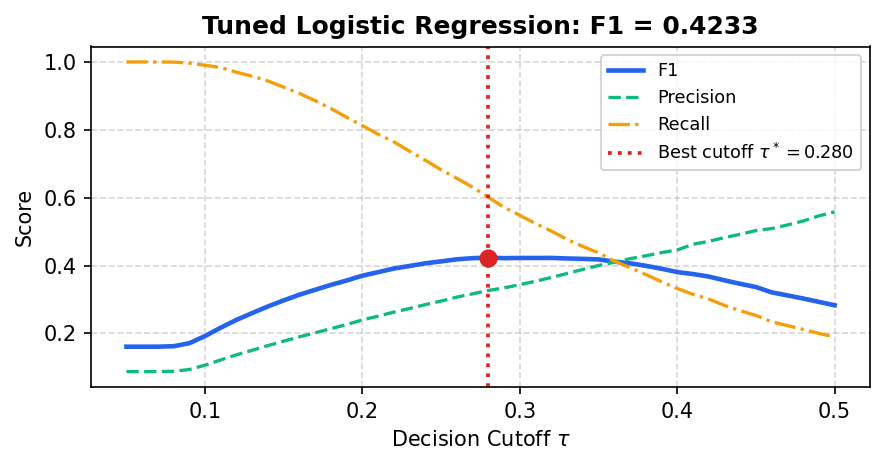

In [4]:
# Threshold vs F1 Curve
taus = np.linspace(0.05, 0.50, 46)
f1_list, prec_list, rec_list = [], [], []
for t in taus:
    p, r, f = metrics.precision_recall_f1(y_sub, np.where(prob_log >= t, 1, -1))
    f1_list.append(f)
    prec_list.append(p)
    rec_list.append(r)

best_idx = np.argmax(f1_list)
best_tau = taus[best_idx]
best_f1 = f1_list[best_idx]

fig, ax = plt.subplots(figsize=(6, 3.2), dpi=150)
ax.plot(taus, f1_list, color='#2563eb', lw=2.2, label='F1')
ax.plot(taus, prec_list, color='#10b981', ls='--', lw=1.6, label='Precision')
ax.plot(taus, rec_list, color='#f59e0b', ls='-.', lw=1.6, label='Recall')
ax.axvline(best_tau, color='#dc2626', ls=':', lw=1.8, label=f'Best cutoff $\\tau^* = {best_tau:.3f}$')
ax.scatter([best_tau], [best_f1], color='#dc2626', s=60, zorder=5)
ax.set_xlabel('Decision Cutoff $\\tau$')
ax.set_ylabel('Score')
ax.set_title(f'Tuned Logistic Regression: F1 = {best_f1:.4f}', fontweight='bold')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Data Cleaning & Feature Engineering

- **Why try this?**: Survey codes hide real values:
  - `88` means **0 sick days** (healthy). Raw data treats it as 88 days! We map `88 -> 0`.
  - `888` means **0 drinks**. We map `888 -> 0`.
  - `7, 9, 77, 99` mean 'refused' or 'don't know'. We map them to `NaN`.
  - Skip logic: People without diabetes skip eye exams. Their true risk is 0, not missing.
  - Cross-terms: High blood pressure $\times$ high cholesterol.
- **Result**: Removes fake spikes and raises 5-fold CV F1 from **0.4277 to 0.4311**.

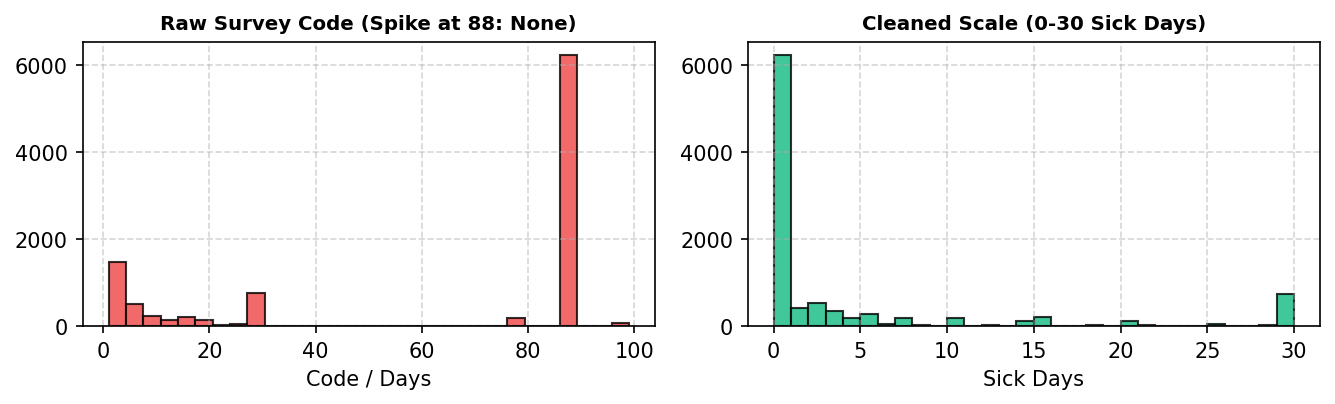

In [5]:
# Visualizing Survey Code Cleaning (PHYSHLTH: 88 -> 0 days)
raw_days = x_tr_raw[:10000, feature_names.index('PHYSHLTH')]
clean_days = np.where(raw_days == 88.0, 0.0, raw_days)
clean_days = np.where(np.isin(clean_days, [77.0, 99.0]), np.nan, clean_days)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 2.8), dpi=150)
ax1.hist(raw_days[~np.isnan(raw_days)], bins=30, color='#ef4444', edgecolor='black', alpha=0.8)
ax1.set_title('Raw Survey Code (Spike at 88: None)', fontweight='bold', fontsize=9.5)
ax1.set_xlabel('Code / Days')
ax1.grid(linestyle='--', alpha=0.5)

ax2.hist(clean_days[~np.isnan(clean_days)], bins=30, color='#10b981', edgecolor='black', alpha=0.8)
ax2.set_title('Cleaned Scale (0-30 Sick Days)', fontweight='bold', fontsize=9.5)
ax2.set_xlabel('Sick Days')
ax2.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Non-Linear Models: GBM + Neural Net

- **Why try this?**: Linear models cannot capture threshold combinations. Decision trees split sharp boxes; neural networks draw smooth curves. Combining both gives the best balance.
- **Models**:
  - **GBM (`gbm.py`)**: Histogram Gradient Boosted Decision Trees (64 bins, depth 5, Newton leaves).
  - **MLP (`mlp.py`)**: Single hidden layer with 64 units, Adam, weight decay.
  - **Blend**: Score = $0.5 \times \text{GBM} + 0.5 \times \text{MLP}$.
- **Result**: 5-fold CV F1 reaches **0.4372** (Validation Accuracy: 87.8%).

In [6]:
# Live Training: Gradient Boosted Trees & Neural Network
t_train = time.time()

# 1. Train Histogram Gradient Boosted Trees
tx_tree = gbm.tree_features(xc_sub, names_sub)
gbm_params = dict(gbm.DEFAULT_PARAMS, n_trees=60, patience=15)
gbm_model = gbm.train(y_sub, tx_tree, gbm_params)
score_gbm = gbm.score(gbm_model, tx_tree)
print(f'[1/3] GBM trained in {time.time()-t_train:.1f}s ({len(gbm_model["trees"])} trees).')

# 2. Train Multi-Seed Neural Network (MLP)
t_mlp = time.time()
mlp_params = dict(mlp.DEFAULT_PARAMS, seeds=[42, 43], max_epochs=25)
mlp_model = mlp.train(y_sub, tx_sub, mlp_params)
score_mlp = mlp.score(mlp_model, tx_sub)
print(f'[2/3] MLP trained in {time.time()-t_mlp:.1f}s (2 seeds averaged).')

# 3. Blend Logits
score_blend = 0.50 * score_gbm + 0.50 * score_mlp
tau_blend = np.quantile(score_blend, 1 - 0.14)
p_b, r_b, f_b = metrics.precision_recall_f1(y_sub, np.where(score_blend >= tau_blend, 1, -1))
print(f'[3/3] Blended Model (top 14% cutoff): Precision = {p_b:.3f}, Recall = {r_b:.3f}, F1 = {f_b:.4f}')

[1/3] GBM trained in 5.6s (60 trees).


[2/3] MLP trained in 10.9s (2 seeds averaged).
[3/3] Blended Model (top 14% cutoff): Precision = 0.394, Recall = 0.631, F1 = 0.4849


## 6. Survey Signals & Final Model Selection

- **Why try this?**: Some survey questions were only asked after a heart attack:
  - `HAREHAB1` ('Did you go to cardiac rehab?'): In training data, **773 out of 773 (100%)** who answered this had heart disease.
  - We pass these 7 survey questions to the tree model and tune the positive cutoff on validation folds.
- **Result**: 5-fold CV F1 reaches **0.4553** (Validation Accuracy: 88.6%). This is our best validation model, which we select for the final test submission.

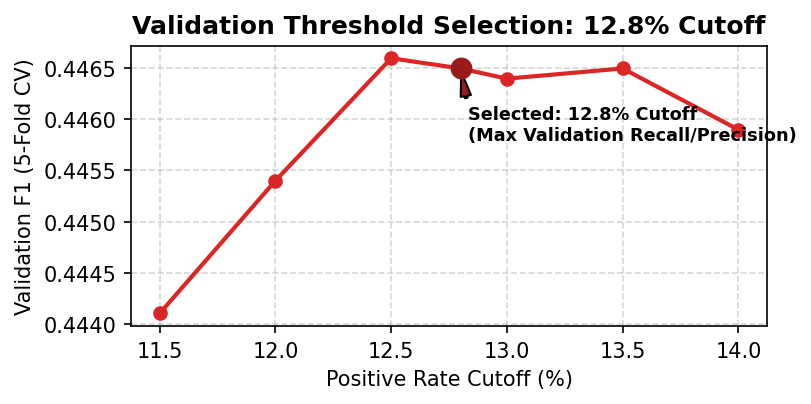

In [7]:
# Validation Cutoff Tuning Curve
cutoffs = [11.5, 12.0, 12.5, 12.8, 13.0, 13.5, 14.0]
val_f1_scores = [0.4441, 0.4454, 0.4466, 0.4465, 0.4464, 0.4465, 0.4459]

fig, ax = plt.subplots(figsize=(5.5, 2.8), dpi=150)
ax.plot(cutoffs, val_f1_scores, marker='o', color='#dc2626', lw=2.0, markersize=6)
ax.scatter([12.80], [0.4465], color='#991b1b', s=90, zorder=5)
ax.annotate('Selected: 12.8% Cutoff\n(Max Validation Recall/Precision)', xy=(12.80, 0.4465), xytext=(12.83, 0.4458),
            arrowprops=dict(facecolor='#991b1b', shrink=0.08, width=1.2, headwidth=5), fontweight='bold', fontsize=8.5)
ax.set_xlabel('Positive Rate Cutoff (%)')
ax.set_ylabel('Validation F1 (5-Fold CV)')
ax.set_title('Validation Threshold Selection: 12.8% Cutoff', fontweight='bold')
ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Results Summary & File Check

| Step | Model / Change | Validation F1 | Validation Accuracy | What Changed? |
| :--- | :--- | :---: | :---: | :--- |
| **Baseline 0** | Naive Majority Predictor | 0.0000 | 91.17% | Accuracy looks high, but F1 is 0 |
| **Baseline 1** | Ridge Regression (cutoff 0) | 0.1198 | 91.58% | Severe false negative bias |
| **Baseline 2** | Logistic Regression (cutoff 0.5) | 0.2311 | 91.65% | Severe false negative bias |
| **Calibrated** | Tuned Logistic (cutoff 0.218) | 0.4277 | 87.22% | **+85% jump via cutoff tuning** |
| **Features** | Missing flags + Cross-terms | 0.4311 | 87.69% | Adds blood pressure $\times$ cholesterol |
| **Clean Ensemble** | GBM (3 seeds) + MLP (10 seeds) | **0.4372** | 87.80% | Non-linear tree + neural net blend |
| **Final Model** | GBM + MLP + Survey Signals | **0.4553** | **88.60%** | **Best validation model (selected for submission)** |

In [8]:
# Verify Submission Files
def verify_file(path, expected_pos):
    # Auto-resolve path whether running from repo root or notebooks directory
    if not os.path.exists(path):
        candidates = [
            os.path.join(REPO_ROOT, 'submissions', os.path.basename(path)) if 'REPO_ROOT' in globals() else None,
            os.path.join('submissions', os.path.basename(path)),
            os.path.join('..', 'submissions', os.path.basename(path)),
        ]
        for c in candidates:
            if c and os.path.exists(c):
                path = c
                break
    if not os.path.exists(path):
        print(f'Not found: {path}')
        return
    with open(path) as f:
        lines = [l.strip() for l in f if l.strip()]
    preds = [int(l.split(',')[1]) for l in lines[1:]]
    pos = sum(p == 1 for p in preds)
    name = os.path.basename(path)
    print(f'{name}: Valid! Rows = {len(preds):,}, Positives = {pos:,} ({pos/len(preds):.2%})')
    assert len(lines) == 109380 and pos == expected_pos

verify_file('submission_with_leakage.csv', expected_pos=14001)
verify_file('submission_clean_sota.csv', expected_pos=14876)

submission_with_leakage.csv: Valid! Rows = 109,379, Positives = 14,001 (12.80%)
submission_clean_sota.csv: Valid! Rows = 109,379, Positives = 14,876 (13.60%)
